# Mirror Dataset Skeleton Viewer

Minimal example for fetching and displaying proofread skeleton data from the mirrored `minnie35` or `v1dd` DataJoint databases.

This notebook uses `connects_neuvue.mirrortables.MirrorTableAPI`, which reflects the database with DataJoint virtual modules and configures the S3 stores needed for skeleton and graph payloads.

## 1. Imports

In [1]:
import os
from getpass import getpass

import matplotlib.pyplot as plt
import numpy as np

from connects_neuvue import MirrorTableAPI

## 2. Connect To A Mirror Dataset

Set `DATASET` to either `"minnie35"` or `"v1dd"`. The password is read from `DATAJOINT_PASSWORD` if available; otherwise the notebook prompts for it.

In [2]:
DATASET = "minnie35"  # "minnie35" or "v1dd"
AWS_PROFILE = "proof"  # set to None to use the default AWS credential chain

password = os.getenv("DATAJOINT_PASSWORD") or getpass("DataJoint password: ")
secret_dict = {"username": "admin", "password": password}

api = MirrorTableAPI(DATASET, secret_dict=secret_dict, aws_profile=AWS_PROFILE)
api.info

[2026-05-22 02:06:01,609][INFO]: Connecting admin@neurd-datajoint.cluster-cjc6cqmcqirl.us-east-1.rds.amazonaws.com:3306
[2026-05-22 02:06:02,012][INFO]: Connected admin@neurd-datajoint.cluster-cjc6cqmcqirl.us-east-1.rds.amazonaws.com:3306


MirrorDataset(dataset='minnie35', schema_name='minnie35_mirrortables', module_name='minnie35')

## 3. Pick A Neuron

The key comes from `AutoProofreadNeuron.Obj`, where S3-backed skeleton and graph objects live. For `v1dd`, the key includes `decimation_ratio`.

In [3]:
keys = api.autoproof_obj_table.fetch("KEY", limit=10)
keys[:3]

[{'segment_id': 864691137867463828, 'split_index': 0},
 {'segment_id': 864691137871425104, 'split_index': 0},
 {'segment_id': 864691137873537221, 'split_index': 0}]

In [4]:
key = keys[0]
key

{'segment_id': 864691137867463828, 'split_index': 0}

## 4. Fetch Skeleton Data

In [5]:
proofread_skeleton = api.fetch_proofread_skeleton(**key)
node_skeletons = api.skeleton_points_by_graph_node(**key)

print(f"proofread_skeleton shape: {proofread_skeleton.shape}")
print(f"graph nodes with skeleton_data: {len(node_skeletons)}")
print(f"first few nodes: {list(node_skeletons)[:5]}")

proofread_skeleton shape: (1213, 2, 3)
graph nodes with skeleton_data: 10
first few nodes: ['L0_3', 'L0_1', 'L0_4', 'L0_0', 'L0_2']


## 5. Display The Skeleton

`proofread_skeleton` is an `N x 2 x 3` array of line segments. Graph node skeletons are `N x 3` point sequences.

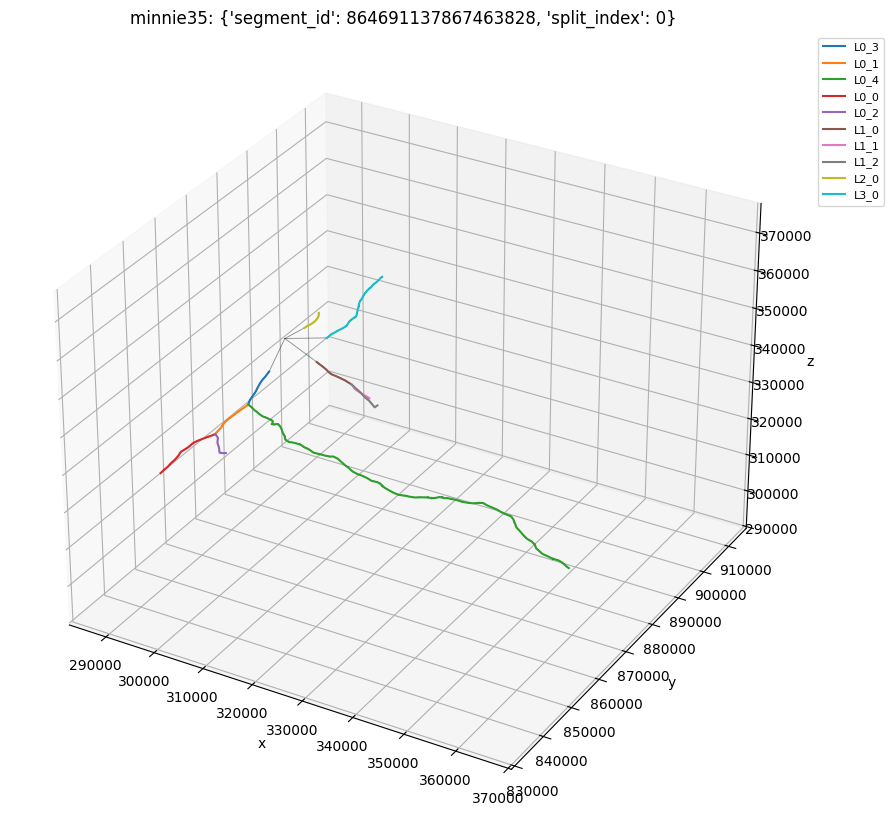

In [6]:
def plot_segment_skeleton(ax, skeleton, *, color="black", linewidth=0.6, alpha=0.45):
    skeleton = np.asarray(skeleton)
    for segment in skeleton:
        ax.plot(segment[:, 0], segment[:, 1], segment[:, 2], color=color, linewidth=linewidth, alpha=alpha)


def set_axes_equal(ax):
    x_limits = ax.get_xlim3d()
    y_limits = ax.get_ylim3d()
    z_limits = ax.get_zlim3d()

    x_range = abs(x_limits[1] - x_limits[0])
    y_range = abs(y_limits[1] - y_limits[0])
    z_range = abs(z_limits[1] - z_limits[0])
    radius = 0.5 * max([x_range, y_range, z_range])

    x_middle = np.mean(x_limits)
    y_middle = np.mean(y_limits)
    z_middle = np.mean(z_limits)

    ax.set_xlim3d([x_middle - radius, x_middle + radius])
    ax.set_ylim3d([y_middle - radius, y_middle + radius])
    ax.set_zlim3d([z_middle - radius, z_middle + radius])


MAX_GRAPH_NODES = 25

fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(111, projection="3d")

plot_segment_skeleton(ax, proofread_skeleton)

for node_name, points in list(node_skeletons.items())[:MAX_GRAPH_NODES]:
    points = np.asarray(points)
    ax.plot(points[:, 0], points[:, 1], points[:, 2], linewidth=1.5, label=node_name)

ax.set_title(f"{DATASET}: {key}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
set_axes_equal(ax)

if len(node_skeletons) <= MAX_GRAPH_NODES:
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), fontsize=8)

plt.tight_layout()
plt.show()

## 6. Display One Graph Node

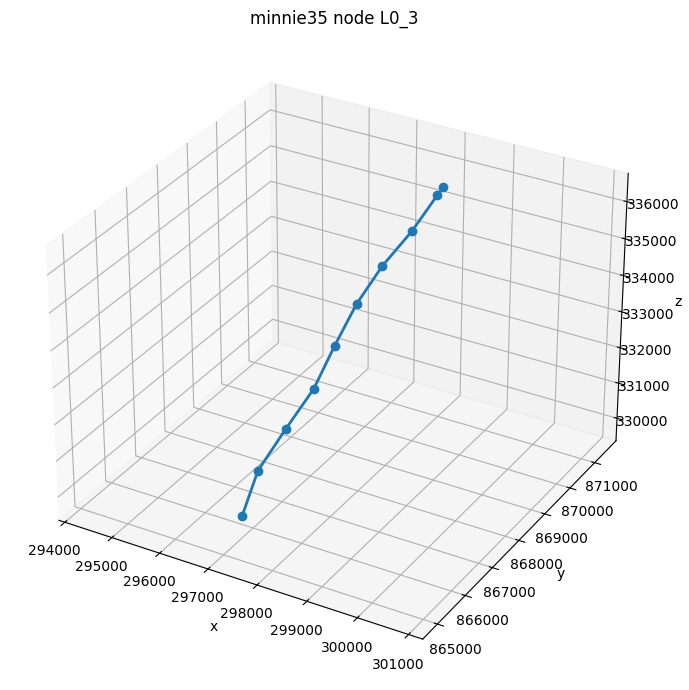

In [7]:
NODE_NAME = next(iter(node_skeletons))
node_points = api.skeleton_points_from_graph_node(node_name=NODE_NAME, **key)

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot(node_points[:, 0], node_points[:, 1], node_points[:, 2], marker="o", linewidth=2)
ax.set_title(f"{DATASET} node {NODE_NAME}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
set_axes_equal(ax)
plt.tight_layout()
plt.show()